In [30]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [31]:
import pandas as pd

df = pd.read_csv("Sample - Superstore.csv", encoding="latin-1")
print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,262,2,0,42
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",732,3,0,220
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,15,2,0,7
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,958,5,0,-383
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22,2,0,3


In [32]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [33]:
print("Missing values per column:")
print(df.isnull().sum())
print("Duplicate rows:", df.duplicated().sum())

Missing values per column:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64
Duplicate rows: 0


In [34]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
df["Year"] = df["Order Date"].dt.year
df["Order Date"].min(), df["Order Date"].max()

(Timestamp('2014-01-03 00:00:00'), Timestamp('2017-12-30 00:00:00'))

In [35]:
total_sales = df["Sales"].sum()
total_profit = df["Profit"].sum()
margin = total_profit / total_sales * 100

print(f"Total sales:  ${total_sales:,.0f}")
print(f"Total profit: ${total_profit:,.0f}")
print(f"Profit margin: {margin:.1f}%")

Total sales:  $2,297,201
Total profit: $286,397
Profit margin: 12.5%


# No missing values, no duplicates. The data is clean.
# Dates: Jan 3, 2014 to Dec 30, 2017, which is 4 full years.
# Sales $2,297,201, profit $286,397, margin 12.5%. For every $100 of sales, the company keeps about $12.50 as profit. The other $87.50 goes to costs.

# Where the Company Loses Money 

In [36]:
by_cat = df.groupby("Category")[["Sales", "Profit"]].sum()
by_cat["Margin %"] = (by_cat["Profit"] / by_cat["Sales"] * 100).round(1)
by_cat.sort_values("Profit", ascending=False)

,Sales,Profit,Margin %
Category,,,
Technology,"836,154","145,455",17
Office Supplies,"719,047","122,491",17
Furniture,"742,000","18,451",2


# Profit by Region

In [37]:
by_region = df.groupby("Region")[["Sales", "Profit"]].sum()
by_region["Margin %"] = (by_region["Profit"] / by_region["Sales"] * 100).round(1)
by_region.sort_values("Profit", ascending=False)

,Sales,Profit,Margin %
Region,,,
West,"725,458","108,418",15
East,"678,781","91,523",14
South,"391,722","46,749",12
Central,"501,240","39,706",8


In [38]:
by_sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum()
by_sub["Margin %"] = (by_sub["Profit"] / by_sub["Sales"] * 100).round(1)
by_sub.sort_values("Profit")

,Sales,Profit,Margin %
Sub-Category,,,
Tables,"206,966","-17,725",-9
Bookcases,"114,880","-3,473",-3
Supplies,"46,674","-1,189",-2
Fasteners,"3,024",950,31
Machines,"189,239","3,385",2
Labels,"12,486","5,546",44
Art,"27,119","6,528",24
Envelopes,"16,476","6,964",42
Furnishings,"91,705","13,059",14


# Do Discounts Hurt Profit? 

In [39]:
df["Discount Level"] = pd.cut(
    df["Discount"],
    bins=[-0.01, 0, 0.2, 0.4, 1],
    labels=["No discount", "1-20%", "21-40%", "Over 40%"]
)

by_disc = df.groupby("Discount Level", observed=True)[["Sales", "Profit"]].sum()
by_disc["Margin %"] = (by_disc["Profit"] / by_disc["Sales"] * 100).round(1)
by_disc

,Sales,Profit,Margin %
Discount Level,,,
No discount,"1,087,908","320,988",30
1-20%,"846,522","100,785",12
21-40%,"234,138","-35,817",-15
Over 40%,"128,632","-99,559",-77


In [40]:
df.groupby("Region")["Discount"].mean().round(3).sort_values()

Region
West      0
East      0
South     0
Central   0
Name: Discount, dtype: float64

# No discount: a 29.5% margin, very healthy.
# 1–20% discount: still profitable, 11.9%.
# 21–40% discount: the company loses money (−15.3%).
# Over 40% discount: it loses 77 cents on every dollar sold (−77.4%).
# Central gives the biggest average discount (24%), about twice the West’s (10.9%). That explains why Central has the weakest margin.

In [41]:
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("images", exist_ok=True)
pd.options.display.float_format = "{:,.0f}".format

# Profit by Sub-category

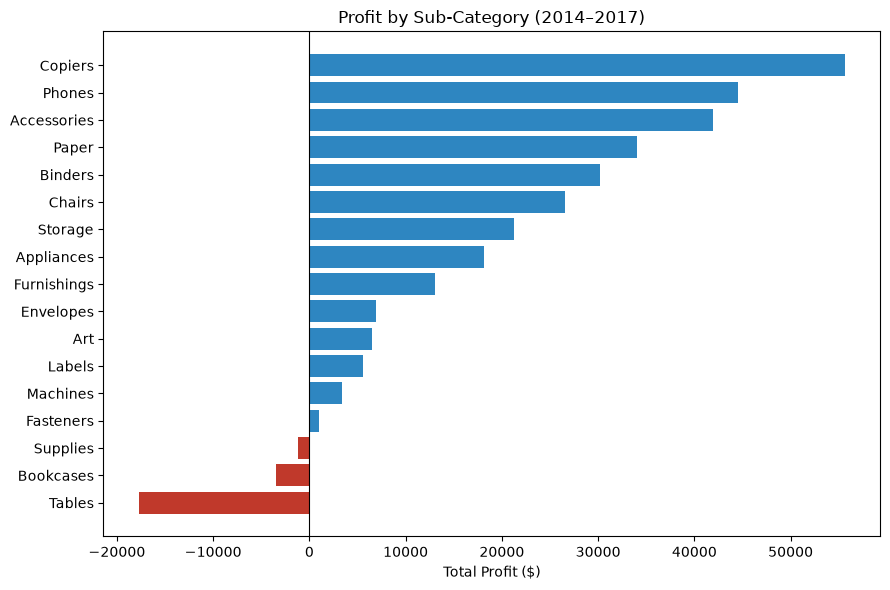

In [42]:
plot_data = by_sub.sort_values("Profit")
colors = ["#C0392B" if p < 0 else "#2E86C1" for p in plot_data["Profit"]]

plt.figure(figsize=(9, 6))
plt.barh(plot_data.index, plot_data["Profit"], color=colors)
plt.axvline(0, color="black", linewidth=0.8)
plt.title("Profit by Sub-Category (2014–2017)")
plt.xlabel("Total Profit ($)")
plt.tight_layout()
plt.savefig("images/profit_by_subcategory.png", dpi=150)
plt.show()

# Profit Margin by Discount Level

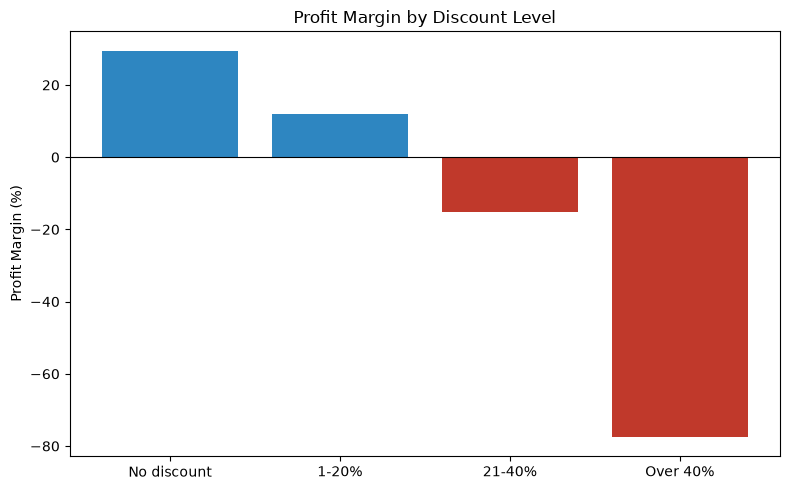

In [43]:
plt.figure(figsize=(8, 5))
colors = ["#2E86C1" if m > 0 else "#C0392B" for m in by_disc["Margin %"]]
plt.bar(by_disc.index.astype(str), by_disc["Margin %"], color=colors)
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Profit Margin by Discount Level")
plt.ylabel("Profit Margin (%)")
plt.tight_layout()
plt.savefig("images/margin_by_discount.png", dpi=150)
plt.show()

# Average Discount vs. Margin by Region

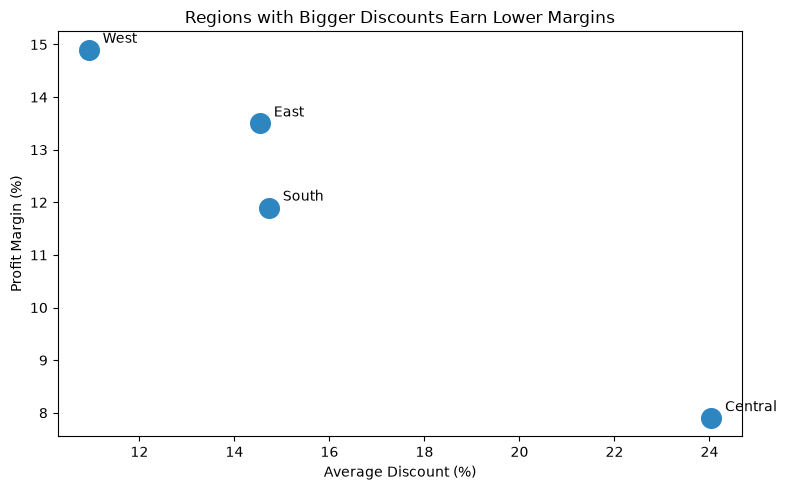

In [44]:
region = by_region.copy()
region["Avg Discount %"] = df.groupby("Region")["Discount"].mean() * 100

fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(region["Avg Discount %"], region["Margin %"], s=200, color="#2E86C1")
for name, row in region.iterrows():
    ax.annotate(name, (row["Avg Discount %"], row["Margin %"]),
                textcoords="offset points", xytext=(10, 5))
ax.set_title("Regions with Bigger Discounts Earn Lower Margins")
ax.set_xlabel("Average Discount (%)")
ax.set_ylabel("Profit Margin (%)")
plt.tight_layout()
plt.savefig("images/region_discount_vs_margin.png", dpi=150)
plt.show()